Implement XGBoost classifiers, applying early stopping, regularization, and cross-validation for highly optimized predictive modeling on complex, imbalanced datasets.

In [12]:
import pandas as pd
import numpy as np

In [13]:
np.random.seed(42)

In [14]:
n_samples = 1000

In [15]:
age = np.random.normal(58, 14, n_samples).clip(18, 90)
dosage_mg = np.random.uniform(10, 200, n_samples)
renal_clearance = np.random.normal(80, 25, n_samples).clip(15, 140)
polypharmacy_count = np.random.poisson(lam=4, size=n_samples).clip(1, 12)
biomarker_ratio = np.random.exponential(scale=1.5, size=n_samples)

In [16]:
adverse_logits = (
    0.03 * (age - 58)
    + 0.02 * dosage_mg
    - 0.04 * renal_clearance
    + 0.4 * polypharmacy_count
    + 0.6 * biomarker_ratio
    - 6.5 
)

In [17]:
probs = 1 / (1 + np.exp(-adverse_logits))
target = (probs > np.random.uniform(0, 1, n_samples)).astype(int)

In [18]:
df_xgb = pd.DataFrame({
    'age': age.round(1),
    'dosage_mg': dosage_mg.round(1),
    'renal_clearance': renal_clearance.round(1),
    'polypharmacy_count': polypharmacy_count,
    'biomarker_ratio': biomarker_ratio.round(3),
    'adverse_event': target
})

In [19]:
neg_count, pos_count = np.bincount(df_xgb['adverse_event'])
scale_pos_weight_value = neg_count / pos_count

In [20]:
print("Dataset Shape:", df_xgb.shape)
print(f"Class Distribution: Negative={neg_count}, Positive={pos_count} (Ratio: {neg_count/pos_count:.2f}:1)")
print(f"Calculated `scale_pos_weight` for XGBoost: {scale_pos_weight_value:.2f}")

Dataset Shape: (1000, 6)
Class Distribution: Negative=971, Positive=29 (Ratio: 33.48:1)
Calculated `scale_pos_weight` for XGBoost: 33.48


In [21]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.Defaulting to user installation because normal site-packages is not writeable



In [22]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score

In [23]:
X = df_xgb.drop(columns=['adverse_event'])
y = df_xgb['adverse_event']

In [24]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [25]:
baseline_xgb = xgb.XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=scale_pos_weight_value,
    early_stopping_rounds=10,  # Defined here to activate best_iteration tracking
    eval_metric='logloss',
    random_state=42
)

In [26]:
baseline_xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50
)

[0]	validation_0-logloss:0.65235
[50]	validation_0-logloss:0.19377
[100]	validation_0-logloss:0.15377
[126]	validation_0-logloss:0.15267


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=10,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=500, n_jobs=None,
              num_parallel_tree=None, ...)

In [27]:
print(f"\nOptimal boosting iterations stopped at: {baseline_xgb.best_iteration}")


Optimal boosting iterations stopped at: 116


In [28]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

In [29]:
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 6, 8],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_alpha': [0.0, 0.1, 1.0, 5.0],    
    'reg_lambda': [0.1, 1.0, 5.0, 10.0],   
    'min_child_weight': [1, 3, 5]
}

In [30]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search_xgb = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight_value,
    random_state=42,
    eval_metric='logloss'
)

In [31]:
random_search = RandomizedSearchCV(
    estimator=search_xgb,
    param_distributions=param_dist,
    n_iter=20,
    scoring='average_precision',  # PR-AUC optimal for imbalanced targets
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1
)

In [32]:
random_search.fit(X_train, y_train)
best_xgb = random_search.best_estimator_

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:528: FitFailedWarning: 
2 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\ProgramData\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\rutva\AppData\Roaming\Python\Python313\site-packages\xgboost\core.py", line 569, in inner_f
    return func(**kwargs)
  File "C:\Users\rutva\AppData\Roaming\Python\Python313\site-packages\xgboost\sklearn.py", line 1838, in fit
    train_dmatrix

In [33]:
print("Best Parameters:", random_search.best_params_)
print(f"Best 5-Fold Stratified CV PR-AUC: {random_search.best_score_:.4f}")

Best Parameters: {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best 5-Fold Stratified CV PR-AUC: 0.4533


In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay, confusion_matrix, classification_report, roc_auc_score, average_precision_score

In [35]:
y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

In [36]:
print(f"ROC-AUC Score : {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC Score  : {average_precision_score(y_test, y_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['No Adverse Event', 'Adverse Event']))

ROC-AUC Score : 0.9777
PR-AUC Score  : 0.5833

Classification Report:
                  precision    recall  f1-score   support

No Adverse Event       0.98      1.00      0.99       146
   Adverse Event       1.00      0.25      0.40         4

        accuracy                           0.98       150
       macro avg       0.99      0.62      0.69       150
    weighted avg       0.98      0.98      0.97       150



In [37]:
print("Confusion Matrix:")
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['Actual No Event', 'Actual Event'],
    columns=['Pred No Event', 'Pred Event']
)
print(cm)

Confusion Matrix:
                 Pred No Event  Pred Event
Actual No Event            146           0
Actual Event                 3           1


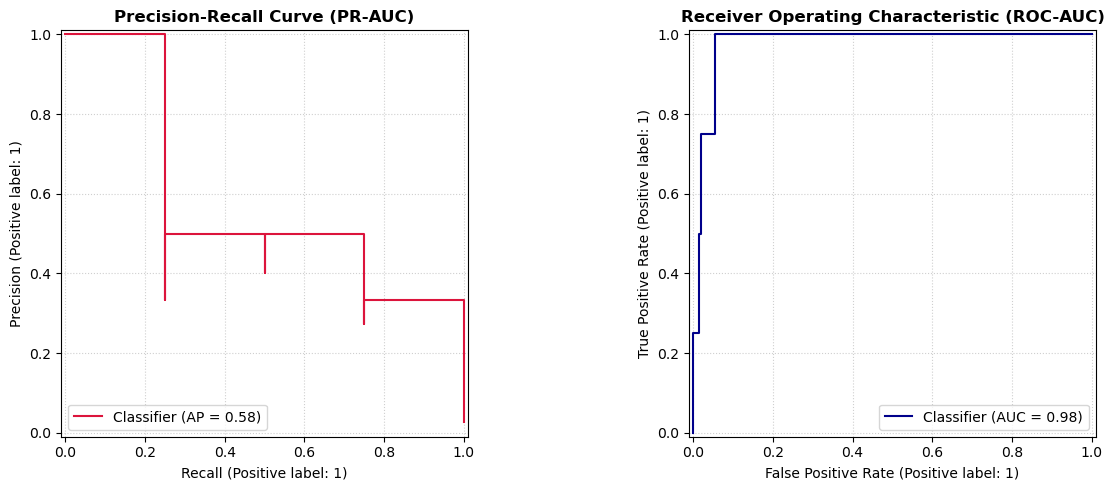

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[0], color='crimson')
axes[0].set_title("Precision-Recall Curve (PR-AUC)", fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], color='darkblue')
axes[1].set_title("Receiver Operating Characteristic (ROC-AUC)", fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

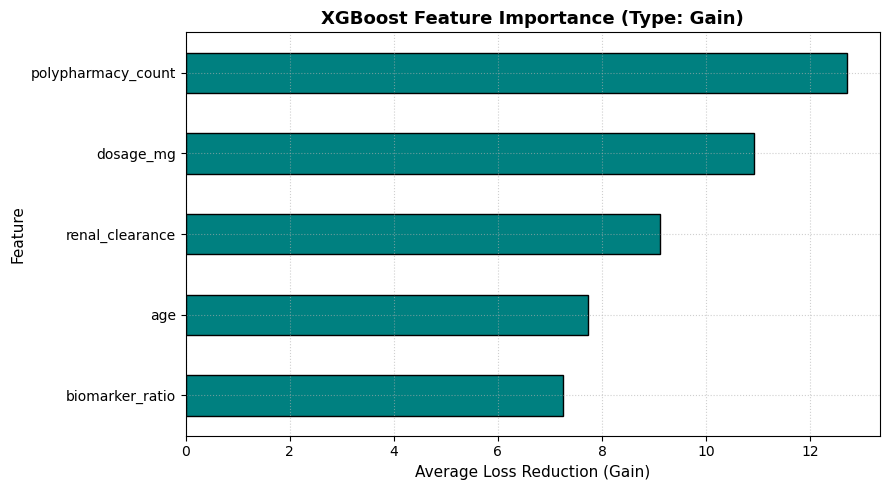

In [39]:
importance_gain = pd.Series(
    best_xgb.get_booster().get_score(importance_type='gain')
).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
importance_gain.plot(kind='barh', color='teal', edgecolor='black')

plt.title("XGBoost Feature Importance (Type: Gain)", fontsize=13, fontweight='bold')
plt.xlabel("Average Loss Reduction (Gain)", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()